In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

c:\Users\lenovo\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
df=pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv')

In [ ]:
#using only the relevant columns for regression
df=df[['engine_displacement','horsepower','vehicle_weight','model_year','fuel_efficiency_mpg']]

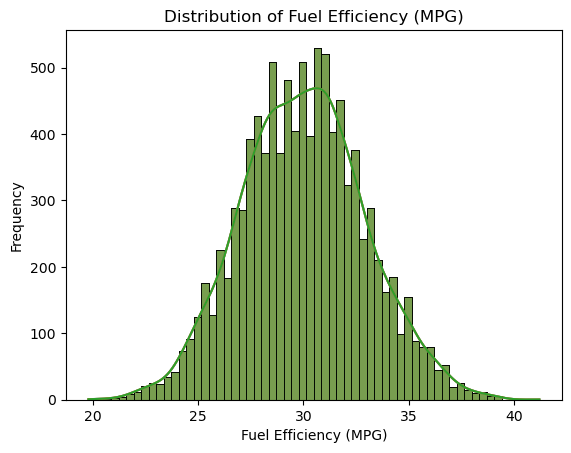

In [9]:
#plotting the distribution of the target variable
sns.histplot(df['fuel_efficiency_mpg'], kde=True)
plt.title('Distribution of Fuel Efficiency (MPG)')
plt.xlabel('Fuel Efficiency (MPG)')
plt.ylabel('Frequency')
plt.show()

In [10]:
#finding columns with missing values
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [12]:
#median of horsepower
median=df['horsepower'].median()
print("Median of horsepower:", median)

Median of horsepower: 254.0


In [13]:
#shuffling the dataset and splitting it into train, validation, and test sets
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [14]:
#target variable
y_train = df_train['fuel_efficiency_mpg'].values
y_val = df_val['fuel_efficiency_mpg'].values
y_test = df_test['fuel_efficiency_mpg'].values

In [15]:
#deleting the target variable from the feature sets
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [16]:
#linear regression model using the normal equation
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]

In [17]:
#filling missing values in 'horsepower' column with 0 and training the model
X_train = df_train.fillna(0).values
w0, w = train_linear_regression(X_train, y_train)



In [18]:
#predicting on the validation set
X_val = df_val.fillna(0).values
y_pred = w0 + X_val.dot(w)

In [19]:
#rmse
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [21]:
#calculating RMSE on the validation set
rmse_val1 = rmse(y_val, y_pred)
print("RMSE on validation set (missing values filled with 0):", round(rmse_val1, 3))

RMSE on validation set (missing values filled with 0): 2.205


In [22]:
#filling missing values in 'horsepower' column with mean and training the model
X_train = df_train.fillna(df_train['horsepower'].mean()).values
w0, w = train_linear_regression(X_train, y_train)

In [23]:
#predicting on the validation set
X_val = df_val.fillna(df_train['horsepower'].mean()).values
y_pred = w0 + X_val.dot(w)

In [24]:
#calculating RMSE on the validation set
rmse_val = rmse(y_val, y_pred)
print("RMSE on validation set(filled with mean):", round(rmse_val, 3))

RMSE on validation set(filled with mean): 2.202


In [25]:
#regularization using missing values filled with 0
X_train = df_train.fillna(0).values

In [26]:
r=[0, 0.01, 0.1, 1, 5, 10, 100]

In [27]:
#linear regression model using the normal equation and regularization
def train_linear_regression_reg(X, y, r):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]

In [ ]:
#usin different values of r to train the model and calculate RMSE on the validation set
for r in r:
    w0, w = train_linear_regression_reg(X_train, y_train, r)

    #predicting on the validation set
    X_val = df_val.fillna(0).values
    y_pred = w0 + X_val.dot(w)

    #calculating RMSE on the validation set
    rmse_val = rmse(y_val, y_pred)
    print("RMSE on validation set (r={}): {}".format(r, round(rmse_val, 4)))

RMSE on validation set (r=0): 2.2053
RMSE on validation set (r=0.01): 2.2058
RMSE on validation set (r=0.1): 2.2241
RMSE on validation set (r=1): 2.3492
RMSE on validation set (r=5): 2.4094
RMSE on validation set (r=10): 2.4195
RMSE on validation set (r=100): 2.4292


In [57]:
#function to generate train, validation, and test splits on different seeds

def generate_splits(df,s):
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(s)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]
    
    #target variable
    y_train = df_train['fuel_efficiency_mpg'].values
    y_val = df_val['fuel_efficiency_mpg'].values
    y_test = df_test['fuel_efficiency_mpg'].values

    #deleting the target variable from the feature sets
    del df_train['fuel_efficiency_mpg']
    del df_val['fuel_efficiency_mpg']
    del df_test['fuel_efficiency_mpg']

    return df_train, df_val, y_train, y_val, df_test, y_test

In [58]:
seeds = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
scores = []                      # empty list to collect one RMSE per seed

for s in seeds:
    # 1. split the data using this seed
    df_train, df_val, y_train, y_val, df_test, y_test = generate_splits(df, s)

    # 2. fill missing values and turn into NumPy matrices
    X_train = df_train.fillna(0).values
    X_val = df_val.fillna(0).values

    # 3. train on train, predict on validation
    w0, w = train_linear_regression(X_train, y_train)
    y_pred = w0 + X_val.dot(w)

    # 4. score and store
    score = rmse(y_val, y_pred)
    scores.append(round(score, 3))



In [59]:
#standard deviation of the RMSE scores across different seeds
round(np.array(scores).std(), 3)

np.float64(0.029)

In [60]:
#spliiting the data using seed 9
df_train, df_val, y_train, y_val, df_test, y_test = generate_splits(df, 9)

In [61]:
#stacking the train and validation sets to create a new training set
df_train_full = pd.concat([df_train, df_val])
#stacling the target variable for the new training set
y_train_full = np.concatenate([y_train, y_val])

In [62]:
#training the model on new training set with missing values filled with 0 and r=0.001
w0, w = train_linear_regression_reg(df_train_full.fillna(0).values, y_train_full, r=0.001)

In [64]:
#filling the missing values in the test set with 0 and predicting on the test set
X_test = df_test.fillna(0).values
y_pred = w0 + X_test.dot(w)

In [65]:
#calculating RMSE on the test set
rmse_test = rmse(y_test, y_pred)

In [66]:
print("RMSE on test set (missing values filled with 0 and r=0.001):", round(rmse_test, 3))

RMSE on test set (missing values filled with 0 and r=0.001): 2.236
